In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)

data = iris['data']
y = iris['target'].values

In [3]:
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
y[:5]

array([0, 0, 0, 0, 0])

# Задание 1

Перейдём к задаче бинарной классификации: будем предсказывать принадлежность цветка к виду versicolor против принадлежности ко всем прочим видам. Перекодируйте зависимую переменную так, чтобы цветки вида versicolor (y=1) имели метку 1, а прочих видов – метку 0.

In [5]:
y = (y == 1).astype(int)

# Задание 2

Будем работать с двумя признаками: sepal length (cm) и sepal width (cm). Построим диаграмму рассеяния по тренировочной выборке и убедитесь, что данные линейно не разделимы.

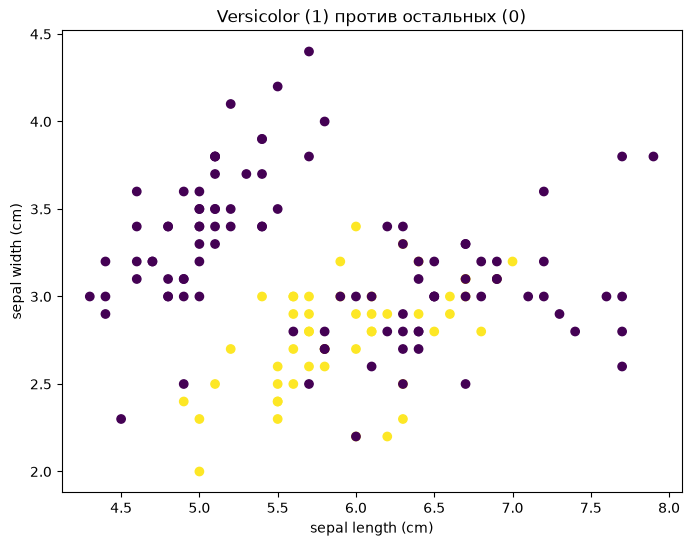

In [6]:
X = data[['sepal length (cm)', 'sepal width (cm)']].values

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Versicolor (1) против остальных (0)')
plt.show()

In [7]:
# делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

Приведем значения всех входных признаков к одному масштабу. Для этого применим функцию StandardScaler. Это преобразование приводит значения каждого признака к нулевому среднему и единичной дисперсии:

$$
X_{new} = \frac{X - \mu}{\sigma}
$$

где, $\mu$ - среднее значение признака

$\sigma$ - стандартное отклонение значений признака

In [8]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(X_train, y_train) # считаем \mu и \sigma

# делаем преобразование данных
X_train_ss = ss.transform(X_train)
X_test_ss = ss.transform(X_test)

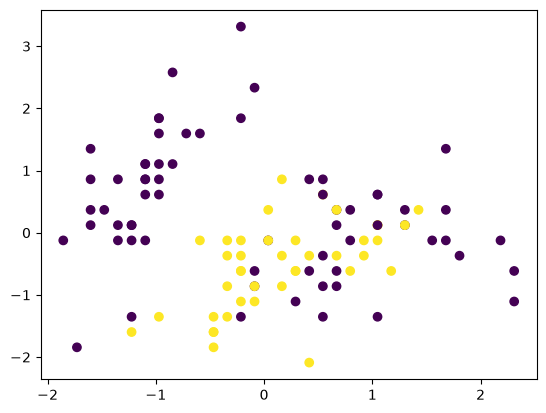

In [9]:
plt.scatter(X_train_ss[:, 0], X_train_ss[:, 1], c=y_train)
plt.show()

# Задание 3

Сравним качество для KNN и логрега.

In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
logreg = LogisticRegression()

### Обучение

In [11]:
knn.fit(X_train_ss, y_train)
logreg.fit(X_train_ss, y_train);

### Прогноз метки класса

In [12]:
# Получите прогнозы для тестовой выборки

y_test_pred_knn = knn.predict(X_test_ss)
y_test_pred_logreg = logreg.predict(X_test_ss)

In [13]:
y_test_pred_knn[:5]

array([0, 1, 0, 1, 0])

In [14]:
y_test_pred_logreg[:5]

array([1, 0, 1, 0, 0])

### Прогноз вероятности класса

In [15]:
# получите прогнозы для тестовой выборки

y_test_proba_knn = knn.predict_proba(X_test_ss)
y_test_proba_logreg = logreg.predict_proba(X_test_ss)

In [16]:
y_test_proba_knn[:5]

array([[1. , 0. ],
       [0.2, 0.8],
       [0.6, 0.4],
       [0. , 1. ],
       [1. , 0. ]])

In [17]:
y_test_proba_logreg[:5]

array([[0.29417961, 0.70582039],
       [0.57205493, 0.42794507],
       [0.46752787, 0.53247213],
       [0.63769064, 0.36230936],
       [0.90567108, 0.09432892]])

### Метрика качества

In [18]:
from sklearn.metrics import accuracy_score
print(f'KNN: {accuracy_score(y_test, y_test_pred_knn)}')
print(f'LogReg: {accuracy_score(y_test, y_test_pred_logreg)}')

KNN: 0.7555555555555555
LogReg: 0.8444444444444444


### Строим разделяющую поверхность

Text(0.5, 1.0, 'Разделяющая поверхность для KNN')

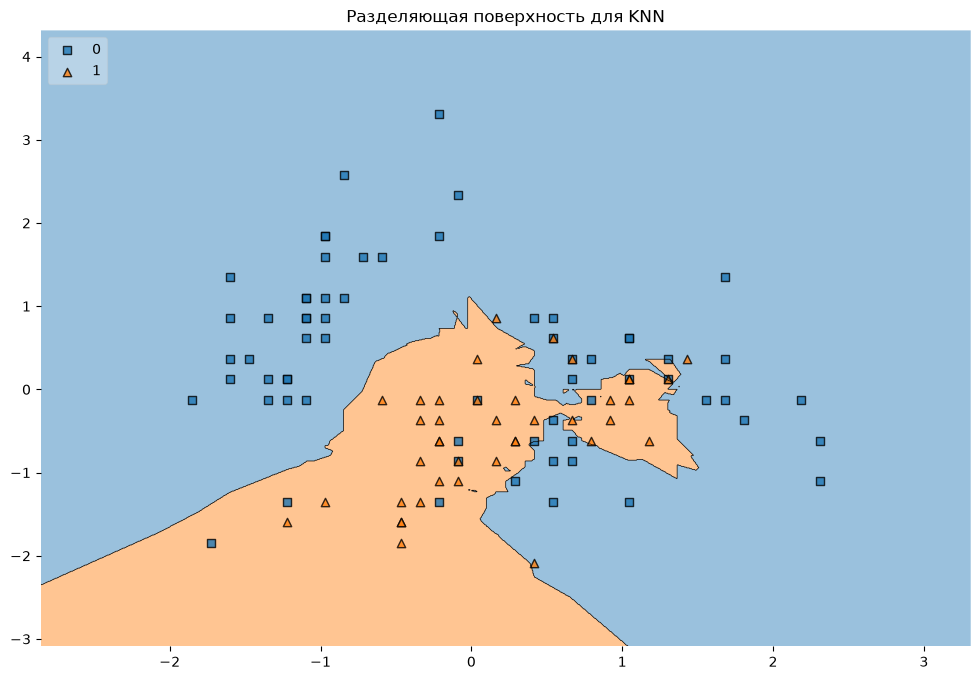

In [19]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train_ss, y_train, clf=knn, legend=2)
plt.title('Разделяющая поверхность для KNN')

Text(0.5, 1.0, 'Разделяющая поверхность для логрега')

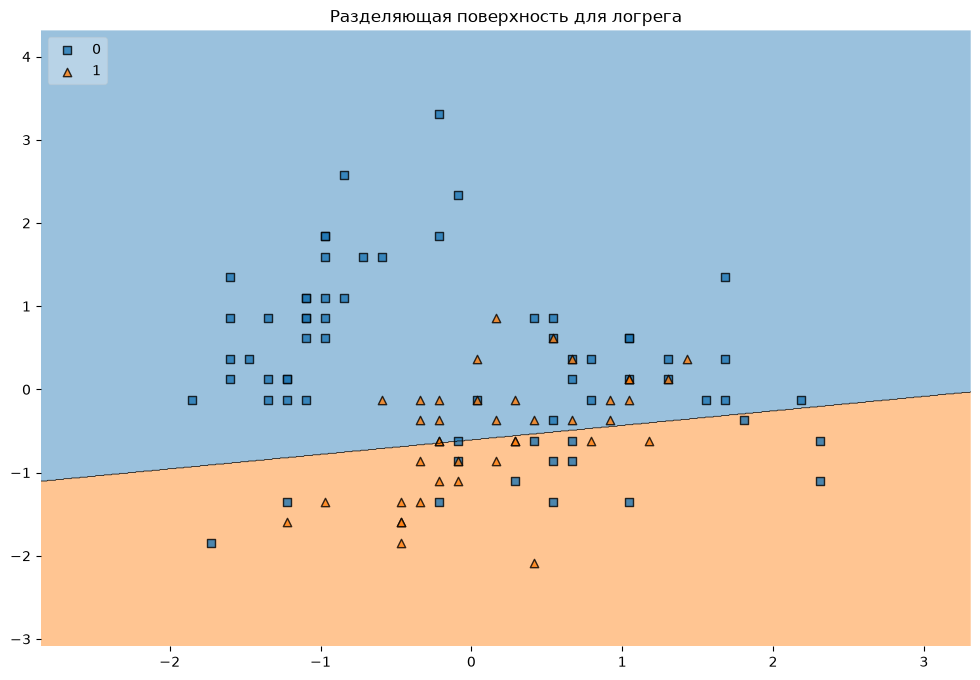

In [20]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train_ss, y_train, clf=logreg, legend=2)
plt.title('Разделяющая поверхность для логрега')

Теперь изучим свойства каждого классификатора по-отдельности. Начнём с логистической регрессии.

### Задание 4.

Обучите три различные логистические регрессии с разным параметром регуляризации C.

In [21]:
# Здесь должен быть ваш код

logreg_1 = LogisticRegression(C=0.01)
logreg_2 = LogisticRegression(C=0.05)
logreg_3 = LogisticRegression(C=10)

Правильность при C=0.01:  0.7777777777777778
Правильность при C=0.05:  0.8444444444444444
Правильность при C=10:  0.8444444444444444


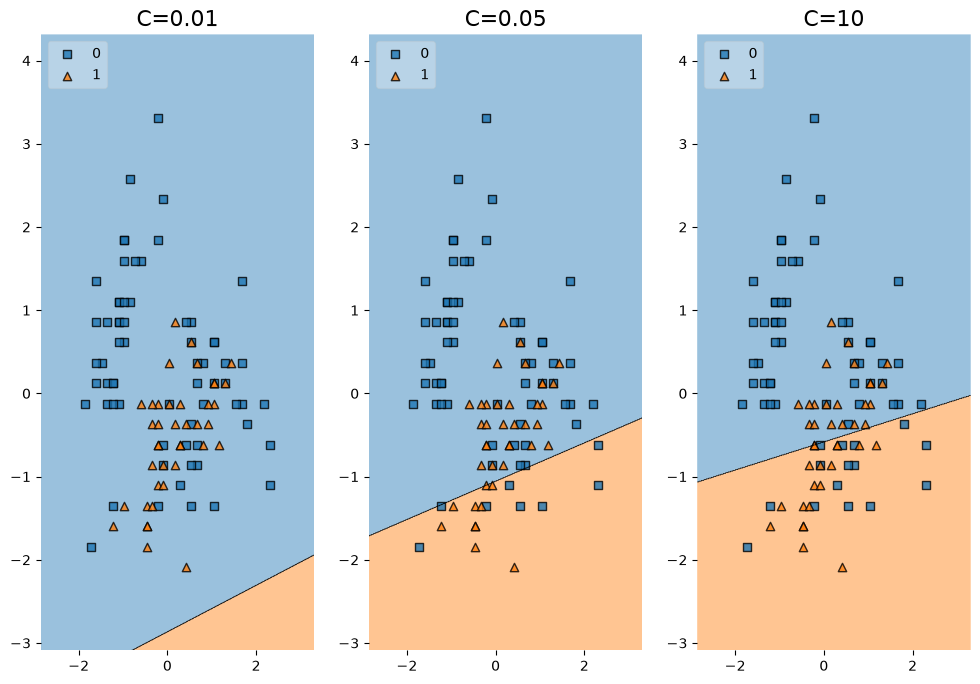

In [22]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 8))
pipes = [logreg_1, logreg_2, logreg_3]

for ind, clf in enumerate(pipes):
    clf.fit(X_train_ss, y_train)
    y_test_pred = clf.predict(X_test_ss)
    score = accuracy_score(y_test, y_test_pred)
    print(f"Правильность при C={clf.get_params()['C']}: ", score)
    fig = plot_decision_regions(X_train_ss, y_train, clf=clf, legend=2, ax=axes[ind])
    fig.set_title(f"C={clf.get_params()['C']}", fontsize=16)

Перейдем к kNN

### Задание 5

Обучите три KNN с разным числом соседей.

In [23]:
# Здесь должен быть ваш код

knn_1 = KNeighborsClassifier(n_neighbors=1)
knn_2 = KNeighborsClassifier(n_neighbors=5)
knn_3 = KNeighborsClassifier(n_neighbors=50)

Правильность при n_neighbors=1:  0.8222222222222222
Правильность при n_neighbors=5:  0.7555555555555555
Правильность при n_neighbors=50:  0.8444444444444444


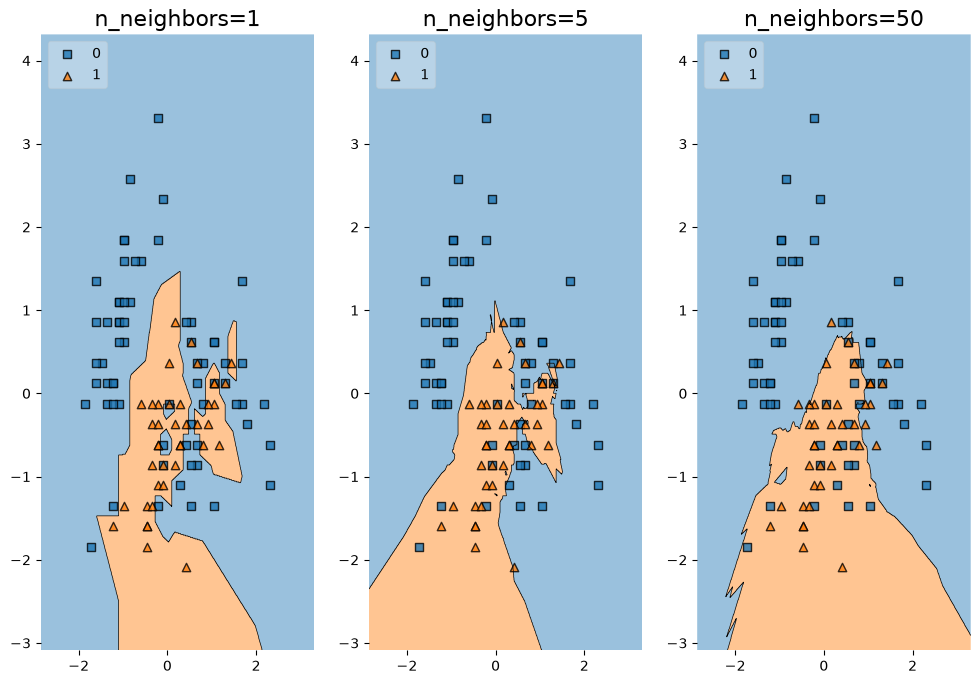

In [24]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 8))
pipes = [knn_1, knn_2, knn_3]

for ind, clf in enumerate(pipes):
    clf.fit(X_train_ss, y_train)
    y_test_pred = clf.predict(X_test_ss)
    score = accuracy_score(y_test, y_test_pred)
    print(f"Правильность при n_neighbors={clf.get_params()['n_neighbors']}: ", score)
    fig = plot_decision_regions(X_train_ss, y_train, clf=clf, legend=2, ax=axes[ind])
    fig.set_title(f"n_neighbors={clf.get_params()['n_neighbors']}", fontsize=16)

### Дополнительные задания

1. Зачем мы используем StandardScaler? Что будет, если один из входных признаков умножить на 10^6?

In [25]:
X_train_big = X_train.copy()
X_test_big = X_test.copy()
X_train_big[:, 0] *= 1e6
X_test_big[:, 0] *= 1e6

# Без масштабирования
knn_big = KNeighborsClassifier(n_neighbors=5).fit(X_train_big, y_train)
logreg_big = LogisticRegression().fit(X_train_big, y_train)
print('KNN без scaler:   ', accuracy_score(y_test, knn_big.predict(X_test_big)))
print('LogReg без scaler:', accuracy_score(y_test, logreg_big.predict(X_test_big)))

# С масштабированием
ss_big = StandardScaler().fit(X_train_big)
X_train_big_ss = ss_big.transform(X_train_big)
X_test_big_ss = ss_big.transform(X_test_big)

knn_big_ss = KNeighborsClassifier(n_neighbors=5).fit(X_train_big_ss, y_train)
logreg_big_ss = LogisticRegression().fit(X_train_big_ss, y_train)
print('KNN со scaler:    ', accuracy_score(y_test, knn_big_ss.predict(X_test_big_ss)))
print('LogReg со scaler: ', accuracy_score(y_test, logreg_big_ss.predict(X_test_big_ss)))

KNN без scaler:    0.5777777777777777
LogReg без scaler: 0.7555555555555555
KNN со scaler:     0.7555555555555555
LogReg со scaler:  0.8444444444444444


2. Найдите оптимальное значение для параметра регуляризации C логистической регрессии

In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': np.logspace(-3, 3, 20)}
gs_logreg = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
gs_logreg.fit(X_train_ss, y_train)

print('Лучшее C:', gs_logreg.best_params_['C'])
print('Лучшая CV-правильность:', gs_logreg.best_score_)
print('Правильность на тесте:', accuracy_score(y_test, gs_logreg.predict(X_test_ss)))

Лучшее C: 0.07847599703514611
Лучшая CV-правильность: 0.6380952380952382
Правильность на тесте: 0.8666666666666667


3. Найдите оптимальное количество соседей K в методе ближайших соседей

Лучшее K: 14
Лучшая CV-правильность: 0.7714285714285714
Правильность на тесте: 0.7333333333333333


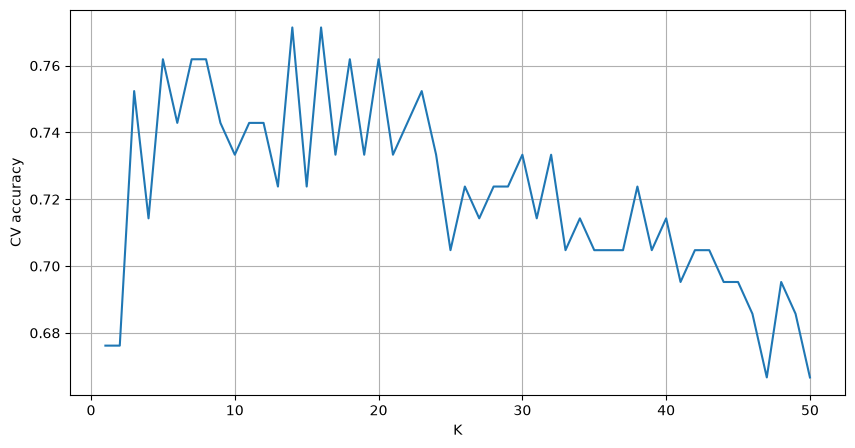

In [27]:
param_grid = {'n_neighbors': range(1, 51)}
gs_knn = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
gs_knn.fit(X_train_ss, y_train)

print('Лучшее K:', gs_knn.best_params_['n_neighbors'])
print('Лучшая CV-правильность:', gs_knn.best_score_)
print('Правильность на тесте:', accuracy_score(y_test, gs_knn.predict(X_test_ss)))

# График зависимости качества от K
plt.figure(figsize=(10, 5))
plt.plot(param_grid['n_neighbors'], gs_knn.cv_results_['mean_test_score'])
plt.xlabel('K')
plt.ylabel('CV accuracy')
plt.grid()
plt.show()

# Нелинейные поверхности

In [28]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=200, shuffle=True, noise = 0.1, factor=0.1)

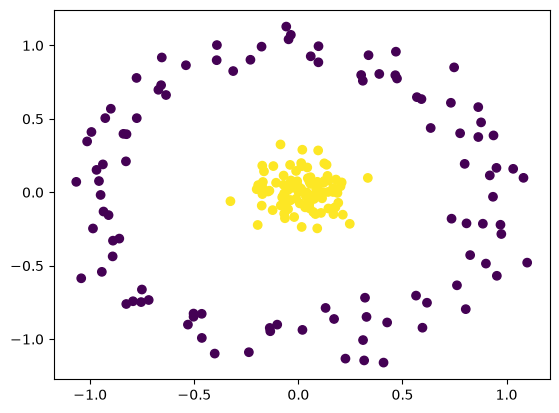

In [29]:
plt.scatter(X[:, 0], X[:, 1], c=y);

In [30]:
# делим данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

In [31]:
# обучаем модель
logreg = LogisticRegression()
logreg.fit(X_train, y_train);

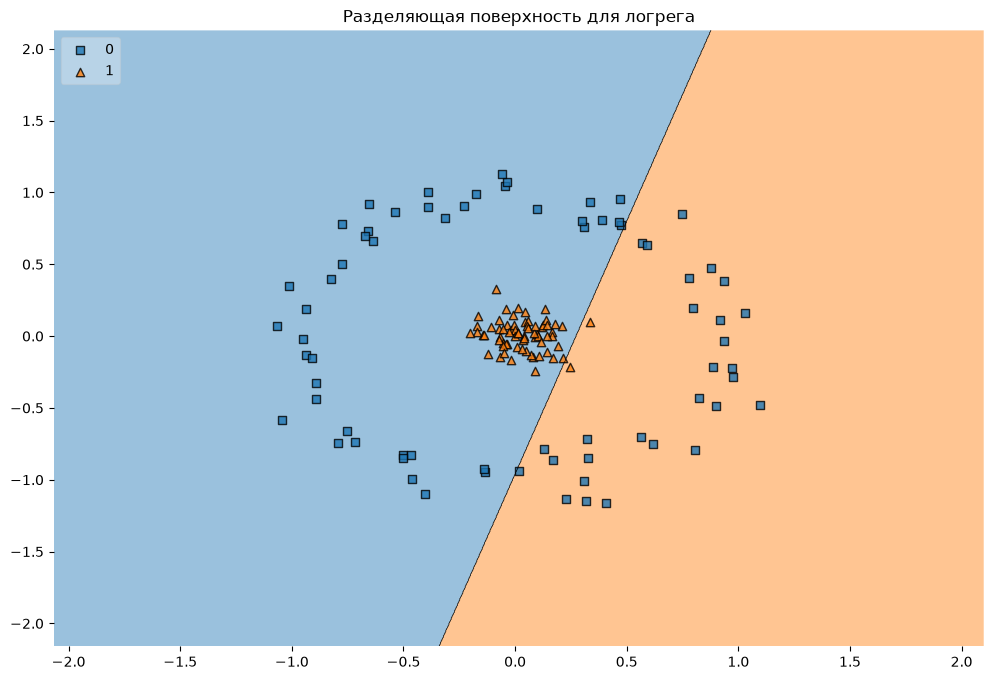

In [32]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train, y_train, clf=logreg, legend=2)
plt.title('Разделяющая поверхность для логрега');

### Добавим новый признак

$$
X_3 = X_1^{2} + X_2^{2}
$$

In [33]:
X1 = X[:,0]
X2 = X[:,1]
X3 = X1**2+X2**2

X_new = np.c_[X1, X2, X3]

In [34]:
# делим данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.3, random_state=123)

### Логистическая регрессия

In [35]:
# обучаем модель
logreg = LogisticRegression()
logreg.fit(X_train, y_train);

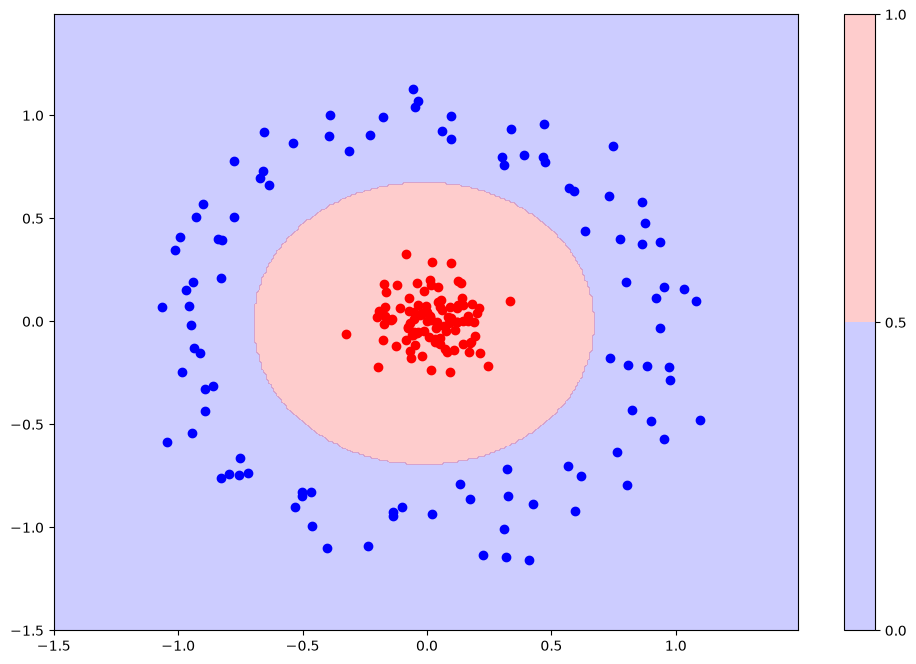

In [36]:
# Plot desicion border

x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01), np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]

y_pred = logreg.predict(X_grid)
y_pred = y_pred.reshape(x0.shape)

plt.figure(figsize=(12,8))
plt.contourf(x0, x1, y_pred, levels=1, cmap=plt.cm.seismic, alpha=0.2)
plt.colorbar()
plt.scatter(X[y==0,0], X[y==0, 1], c='b')
plt.scatter(X[y==1,0], X[y==1, 1], c='r');

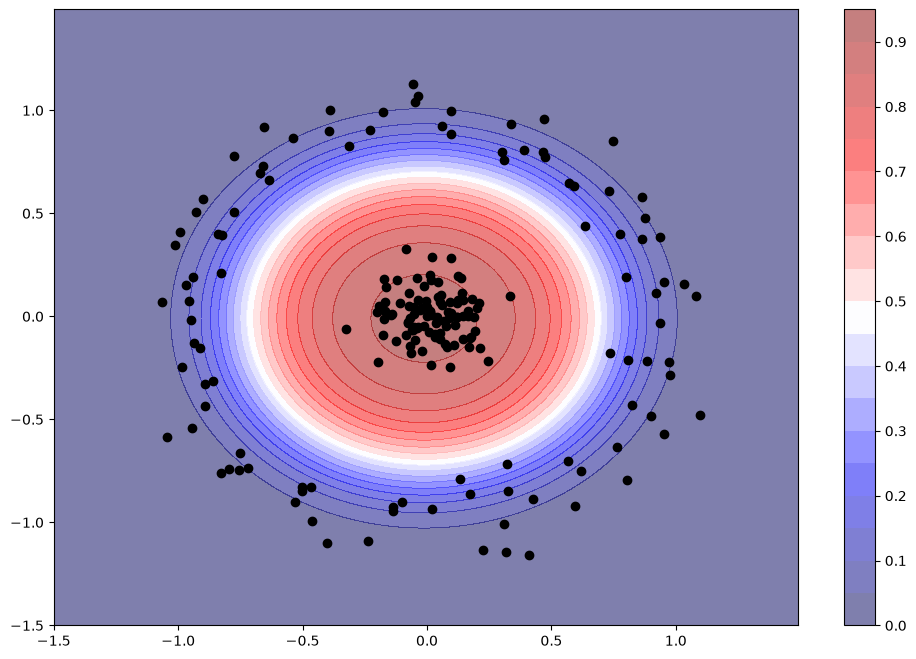

In [37]:
# Plot desicion border

x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01), np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]

y_pred = logreg.predict_proba(X_grid)[:, 1]
y_pred = y_pred.reshape(x0.shape)

plt.figure(figsize=(12,8))
plt.contourf(x0, x1, y_pred, levels=20, cmap=plt.cm.seismic, alpha=0.5)
plt.colorbar()
plt.scatter(X[y==0,0], X[y==0, 1], c='0')
plt.scatter(X[y==1,0], X[y==1, 1], c='0');

# Задание 6

Реализуйте аналогичные вычисления для метода ближайших соседей

Правильность (3 признака): 1.0


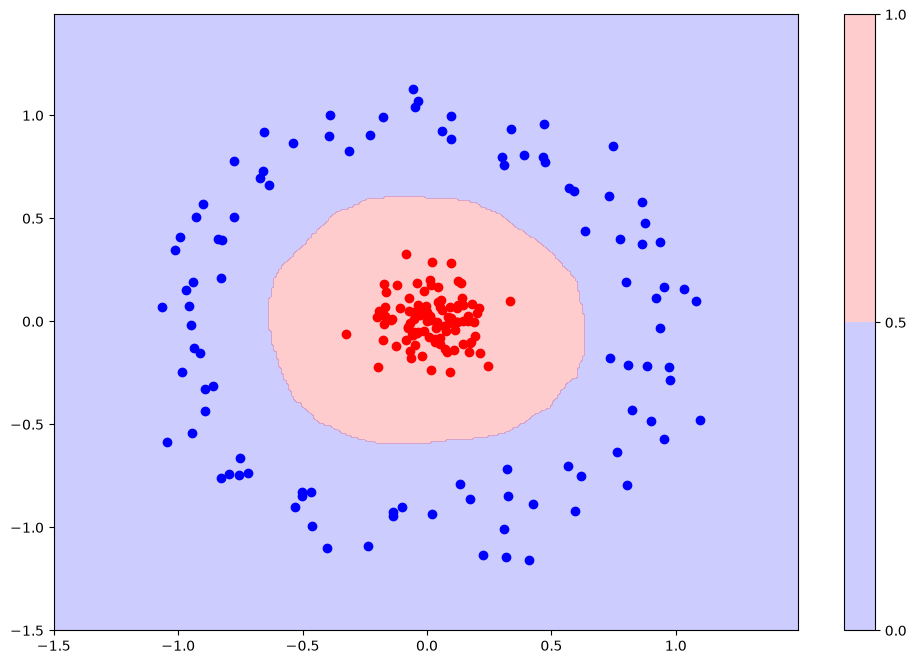

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.3, random_state=123)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print('Правильность (3 признака):', accuracy_score(y_test, knn.predict(X_test)))

# Предсказание классов на сетке
x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01), np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]

y_pred = knn.predict(X_grid).reshape(x0.shape)

plt.figure(figsize=(12, 8))
plt.contourf(x0, x1, y_pred, levels=1, cmap=plt.cm.seismic, alpha=0.2)
plt.colorbar()
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='b')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='r');

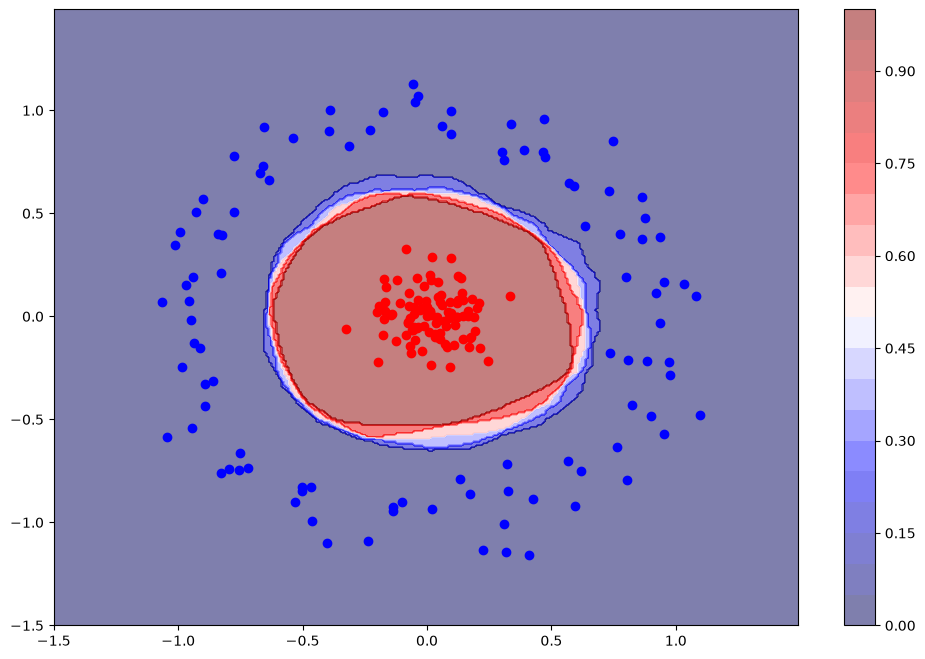

In [39]:
# Предсказание вероятностей на сетке
y_proba = knn.predict_proba(X_grid)[:, 1].reshape(x0.shape)

plt.figure(figsize=(12, 8))
plt.contourf(x0, x1, y_proba, levels=20, cmap=plt.cm.seismic, alpha=0.5)
plt.colorbar()
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='b')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='r');